# Самостоятельная работа: dense GAN на Fashion-MNIST

Здесь требуется самостоятельно перенести алгоритм состязательного
обучения на Fashion-MNIST. Данные отличаются от MNIST-примера, но
размер изображения, нормализация, архитектуры и математические цели
остаются теми же. Заголовки описывают этапы; маркеры «TODO(student)»
расположены только в кодовых ячейках.

Выполняйте задания строго по порядку. На каждом этапе сначала
подтвердите форму тензоров и только потом продолжайте. Метки классов
Fashion-MNIST не становятся целями GAN: задача по-прежнему состоит в
различении реального и синтетического изображения.

## История одного пакета

Генератор превращает пачку случайных карточек `(B,100)` в пачку
картинок `(B,784)`. Дискриминатор смотрит и на эти картинки, и на
настоящие предметы одежды, а затем выдаёт по одному числу `(B,1)`.
Сначала учится проверяющий, потом — художник. Выполняйте этапы именно
по порядку: следующий этап использует объекты, созданные и проверенные
на предыдущем.

### Маленький словарь перед реализацией

Параметры — обучаемые числа в слоях. Прямой проход создаёт картинку и
ответ проверяющего. Потеря — одно число, описывающее ошибку текущего
ответа. Градиент — инструкция, как слегка поменять параметры, чтобы
ошибка уменьшилась. `GradientTape` находит такую инструкцию, а Adam
применяет небольшую поправку.

## Этап 1. Конфигурация независимого эксперимента

**Доступно:** константы ниже. **Цель:** зафиксировать Fashion-MNIST,
первые 10 000 изображений, $d_z=100$, $d_x=784$, пакет 128 и
первоначальные 105 эпох. Для сравнений позднее установите 205 и 400
эпох, не меняя остальную постановку. **Контрольная точка:** диапазон
целевых меток GAN — 0.9, 0 и 1; это не метки предметов одежды.

`(B,784)` означает «B картинок, каждая записана длинной строкой из
784 яркостей», а `(B,1)` — один ответ проверяющего на картинку. Это не
784 разных объектов и не десять классов Fashion-MNIST.

In [1]:
%matplotlib inline

from __future__ import annotations

# Path указывает только место для сеток и графиков. NumPy/Matplotlib
# обслуживают данные и диагностику; TensorFlow строит граф и модели.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Зафиксируйте seed до первого шума и создания слоёв, иначе два
# запуска нельзя будет сравнивать по одним и тем же условиям.
SEED = 42
DATASET_NAME = 'Fashion-MNIST'
MAX_EXAMPLES = 10_000
IMAGE_HEIGHT = 28
IMAGE_WIDTH = 28
# Размерность dense-входа: каждая карта 28×28 станет длиной 784.
IMAGE_DIM = IMAGE_HEIGHT * IMAGE_WIDTH
NOISE_DIM = 100
BATCH_SIZE = 128
EPOCHS = 5
LEARNING_RATE = 2e-4
BETA_1 = 0.5
REAL_LABEL = 0.9
FAKE_LABEL = 0.0
GENERATOR_TARGET = 1.0
SAVE_EVERY = 2

# Keras использует генератор случайных чисел и для весов, и для z.
tf.keras.utils.set_random_seed(SEED)
artifact_dir = Path('artifacts/fashion_mnist_dense_gan')
artifact_dir.mkdir(parents=True, exist_ok=True)

/home/a/.venvs/mfdl/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


I0000 00:00:1795565854.975476   38945 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Этап 2. Получение и подготовка Fashion-MNIST

**Требуется:** получить обучающие изображения Fashion-MNIST, оставить
первые 10 000, преобразовать пиксели из $[0,255]$ в $[-1,1]$ и
развернуть их в $(N,784)$. Затем создайте перемешиваемый набор
мини-пакетов $(B,784)$ без меток классов. **Проверьте:** значения
конечны и принадлежат $[-1,1]$; метки используются только для
необязательной подписи исходных изображений.

**Маршрут:** сначала загрузите массив и посмотрите на одну картинку,
затем приведите значения к `float32`, измените шкалу `[0,255] → [-1,1]`
и лишь потом разверните карту. Останавливайтесь на `assert`: при
неверной форме или диапазоне сеть строить ещё рано. `y_train` не
передаётся GAN, иначе это была бы задача классификации одежды.

In [2]:
# Вход этапа — внешний файл Fashion-MNIST.
(x_train, y_train), _ = tf.keras.datasets.fashion_mnist.load_data()

# Метки y_train оставляем только для подписи исходных картинок: GAN учится без них.
y_train = y_train[:MAX_EXAMPLES]
x_train = x_train[:MAX_EXAMPLES].astype('float32')

# [0, 255] -> [-1, 1] ровно той же линейной формулой, что и в постановке.
x_train = (x_train - 127.5) / 127.5
x_train = x_train.reshape(MAX_EXAMPLES, IMAGE_DIM)

dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(MAX_EXAMPLES, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

first_batch = next(iter(dataset))
print('x_train:', x_train.shape, '| y_train:', y_train.shape)
print('первый пакет:', tuple(first_batch.shape))
print('диапазон:', float(tf.reduce_min(first_batch)), float(tf.reduce_max(first_batch)))

assert x_train.shape == (MAX_EXAMPLES, IMAGE_DIM)
assert tuple(first_batch.shape) == (BATCH_SIZE, IMAGE_DIM)
assert bool(tf.reduce_all(tf.math.is_finite(first_batch)))
assert float(tf.reduce_min(first_batch)) >= -1.0 and float(tf.reduce_max(first_batch)) <= 1.0

x_train: (10000, 784) | y_train: (10000,)
первый пакет: (128, 784)
диапазон: -1.0 1.0


## Этап 3. Генератор и проверка его выхода

**Требуется:** собрать генератор
$100\to256\to512\to1024\to784$ с тремя LeakyReLU и финальным tanh.
Вход — шум $(B,100)$ с независимыми нормальными координатами; выход —
синтетические развёрнутые изображения $(B,784)$ в $[-1,1]$.
Используйте современный tf.keras и не применяйте готовый GAN-слой.
**Контрольная точка:** выход имеет точную форму и не содержит NaN или
бесконечностей.

Считайте `z` карточкой со 100 случайными ручками. В начале генератор
рисует бессмыслицу; обучение понемногу поправляет его веса, чтобы те
же 100 чисел превращались в структуру, похожую на данные. `tanh` не
даёт пикселям покинуть диапазон настоящих картинок.

In [3]:
initializer = tf.keras.initializers.RandomNormal(stddev=0.02)


def make_generator() -> tf.keras.Model:
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(NOISE_DIM,)),
            tf.keras.layers.Dense(256, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dense(512, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dense(1024, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dense(IMAGE_DIM, activation='tanh', kernel_initializer=initializer),
        ],
        name='generator',
    )


generator = make_generator()

z = tf.random.normal((BATCH_SIZE, NOISE_DIM))
diagnostic_images = generator(z, training=False)

print('G(z):', tuple(diagnostic_images.shape))
print('min/max:', float(tf.reduce_min(diagnostic_images)), float(tf.reduce_max(diagnostic_images)))
print('параметров G:', generator.count_params())

assert tuple(diagnostic_images.shape) == (BATCH_SIZE, IMAGE_DIM)
assert bool(tf.reduce_all(tf.math.is_finite(diagnostic_images)))
assert float(tf.reduce_min(diagnostic_images)) >= -1.0
assert float(tf.reduce_max(diagnostic_images)) <= 1.0

G(z): (128, 784)
min/max: -0.0313708558678627 0.03247077763080597
параметров G: 1486352


## Этап 4. Дискриминатор и смысл его выхода

**Требуется:** собрать дискриминатор
$784\to1024\to512\to256\to1$ с LeakyReLU, Dropout(0.3) и sigmoid.
Его входом по очереди будут настоящие и синтетические изображения
$(B,784)$, а результатом — $(B,1)$ вероятностей. Последняя координата
— не класс Fashion-MNIST, а оценка «настоящее».
**Контрольная точка:** на диагностическом входе значения строго между
0 и 1.

Единственный вопрос дискриминатора — «эта картинка пришла из набора
или создана генератором?». Его ответ после sigmoid можно читать как
уверенность от 0 до 1. Это совсем не вероятность одного из классов
одежды и не оценка того, насколько красив предмет.

In [4]:
def make_discriminator() -> tf.keras.Model:
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(IMAGE_DIM,)),
            tf.keras.layers.Dense(1024, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(512, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(256, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(1, activation='sigmoid', kernel_initializer=initializer),
        ],
        name='discriminator',
    )


discriminator = make_discriminator()

real_scores = discriminator(first_batch, training=False)
fake_scores = discriminator(diagnostic_images, training=False)

print('D(real):', tuple(real_scores.shape), '| D(fake):', tuple(fake_scores.shape))
print('вероятности real:', float(tf.reduce_min(real_scores)), float(tf.reduce_max(real_scores)))
print('вероятности fake:', float(tf.reduce_min(fake_scores)), float(tf.reduce_max(fake_scores)))
print('параметров D:', discriminator.count_params())

for scores in (real_scores, fake_scores):
    assert tuple(scores.shape) == (BATCH_SIZE, 1)
    assert bool(tf.reduce_all(tf.math.is_finite(scores)))
    assert float(tf.reduce_min(scores)) > 0.0 and float(tf.reduce_max(scores)) < 1.0

D(real): (128, 1) | D(fake): (128, 1)
вероятности real: 0.4954943358898163 0.5078285932540894
вероятности fake: 0.4999474585056305 0.5000988841056824
параметров D: 1460225


## Этап 5. Две функции потерь и два независимых обновления

**Требуется:** создать BinaryCrossentropy с «from_logits=False» и два
Adam-оптимизатора с заданными learning_rate и beta_1. Напишите
попеременный шаг: сначала обновляет только дискриминатор по настоящим
меткам 0.9 и синтетическим 0; затем обновляет только генератор по
цели 1. Для первого шага отделите синтетические изображения от
градиента генератора. Для второго вызовите дискриминатор с
«training=False», но сохраните прохождение градиента к генератору.

**Контрольная точка:** после первого подшага меняются только
переменные дискриминатора, после второго — только переменные
генератора. Обе потери должны быть конечными скалярами.

**Сначала → затем → проверить.** Сначала выполните фазу D и отделите
созданные картинки через `stop_gradient`: обратная стрелка к G
выключена. Затем создайте новый `GradientTape` для фазы G: стрелка от
ошибки идёт через D к G, но список параметров оптимизатора содержит
только G. Визуальная проверка проста: спросите, какие веса стоят справа
в каждом вызове `apply_gradients`.

Здесь D возвращает вероятность $p$ после sigmoid. Для одной цели $y$
API `BinaryCrossentropy(from_logits=False)` использует

$$
\operatorname{BCE}(y,p)=-y\log p-(1-y)\log(1-p).
$$

Неправильный уверенный ответ получает большую потерю; правильный
уверенный ответ — малую. Для всего мини-пакета TensorFlow усредняет
эту ошибку, получая один скаляр для каждого игрока.

### Математический контракт вашей реализации

**Сначала посмотрите на две фазы глазами данных.**

![Два независимых обновления GAN: обучение дискриминатора, затем обучение генератора](assets/diagrams/gan_two_phase_training.svg)

Эта схема разделяет временные тензоры, скалярные потери и параметры.
Ваша будущая функция не должна пытаться «обучать шум» или метки
Fashion-MNIST: шум — вход, а метки классов вообще не участвуют в GAN.
Обучаемыми остаются только `tf.Variable` внутри G и D.

Обозначим веса и смещения генератора через $\theta_G$, а параметры
дискриминатора — через $\theta_D$. Потеря — один скаляр. Производная
по параметру показывает направление его маленькой поправки:

$$
\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L.
$$

В первой фазе для мини-пакета должны быть вычислены два члена
$\operatorname{BCE}(0.9,D(\mathbf x_{\rm real}))$ и
$\operatorname{BCE}(0,D(G(\mathbf z_D)))$; их среднее образует
$\mathcal L_D$, а градиент запрашивается только по $\theta_D$.
Во второй фазе $\mathcal L_G=\operatorname{BCE}(1,D(G(\mathbf z_G)))$
дифференцируется только по $\theta_G$. Шум — не параметр: каждый
$\mathbf z$ является новым входом формы `(B,100)`.

### Как `GradientTape` превращает loss в поправки весов

![Жизненный цикл GradientTape от прямого прохода до обновления Adam](assets/diagrams/tensorflow_gradient_tape.svg)

`GradientTape` записывает прямой путь вычислений до `loss`, а не
делает отдельное обучение. Пока активен блок `with`, он помнит
дифференцируемые операции и автоматически наблюдает используемые
обучаемые `tf.Variable`. Затем `tape.gradient(loss, variables)`
запускает обратный проход и возвращает по одной производной для
каждого элемента `variables`; форма градиента совпадает с формой
веса. `zip` сопоставляет эти два списка, а `apply_gradients` передаёт
пары Adam. Именно `variables` определяет, обновляется $\theta_G$ или
$\theta_D$; имя tape этого решения не принимает.

Непостоянный tape имеет одно назначение: он нужен для одного вызова
`gradient`, затем его запись освобождается. Это программная запись
правила градиентного шага, а не эвристика TensorFlow. Производные
получаются по цепному правилу: библиотека не выписывает гигантские
якобианы, а передаёт их нужное действие от скалярной потери к весам.

### Один мини-пакет: карта объектов вашей реализации

Используйте эти имена как ориентиры при заполнении TODO. Объекты с
пометкой «временный» не являются параметрами и не передаются Adam.

| Математика | Ожидаемое имя | Форма | Роль в одной фазе |
| --- | --- | --- | --- |
| $\mathbf x_{\rm real}$ | `real_images` | `(B,784)`, `float32` | Настоящие картинки для D. |
| $\mathbf z_D$ | `discriminator_noise` | `(B,100)` | Временный шум фазы D. |
| $G(\mathbf z_D)$ | `fake_images` | `(B,784)` | Подделки после `stop_gradient`. |
| $D(\mathbf x)$ | `real_scores`, `fake_scores` | `(B,1)`, вероятность | Аргумент BCE фазы D. |
| $\mathcal L_D$ | `discriminator_loss` | скаляр | Даёт градиенты только для `discriminator.trainable_variables`. |
| $\mathbf z_G$ | `generator_noise` | `(B,100)` | Новый шум, независимый от $\mathbf z_D$. |
| $G(\mathbf z_G)$ | `generated_images` | `(B,784)` | Подделки, оставленные в графе. |
| $\mathcal L_G$ | `generator_loss` | скаляр | Даёт градиенты только для `generator.trainable_variables`. |

**Проведите одну фазу буквально по строкам.** Сначала внутри первого
`GradientTape` вычисляются входы D и один скаляр `discriminator_loss`.
Затем `tape.gradient(discriminator_loss,
discriminator.trainable_variables)` строит список производных в том же
порядке, что список весов. `zip` образует пары, и только после
`discriminator_optimizer.apply_gradients(...)` меняются $\theta_D$.
Фаза G повторяет эту схему с новым tape, новым шумом и списком весов G.

Для этой модели D выдаёт вероятность, поэтому точный путь градиента
генератора можно записать через якобианы:

$$
\nabla_{\theta_G}\mathcal L_G
=J_{G,\theta_G}^{\mathsf T}J_{D,\mathbf x}^{\mathsf T}
\nabla_{\mathbf p}\mathcal L_G.
$$

Якобиан — таблица всех локальных влияний: как выход меняется при малом
изменении входа. Он слишком велик для явного создания; `gradient`
вычисляет только нужный обратный проход, то есть произведения с ним.

In [5]:
bce = tf.keras.losses.BinaryCrossentropy(from_logits=False)

# Два независимых Adam: состояния моментов G и D не должны смешиваться.
generator_optimizer = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
discriminator_optimizer = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)


@tf.function
def train_step(real_images: tf.Tensor):
    batch_size = tf.shape(real_images)[0]

    # ---- фаза D: обновляются только переменные дискриминатора ----
    z_d = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as discriminator_tape:
        generated = generator(z_d, training=False)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(tf.stop_gradient(generated), training=True)
        real_targets = tf.fill([batch_size, 1], REAL_LABEL)
        discriminator_loss = 0.5 * bce(real_targets, real_output) + 0.5 * bce(
            tf.zeros_like(fake_output), fake_output
        )

    discriminator_gradients = discriminator_tape.gradient(
        discriminator_loss, discriminator.trainable_variables
    )
    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    # ---- фаза G: градиент идёт L_G -> D -> G, но обновляется только G ----
    z_g = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as generator_tape:
        generated = generator(z_g, training=True)
        fake_output = discriminator(generated, training=False)
        generator_loss = bce(tf.ones_like(fake_output), fake_output)

    generator_gradients = generator_tape.gradient(
        generator_loss, generator.trainable_variables
    )
    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )

    return discriminator_loss, generator_loss


d_probe, g_probe = train_step(first_batch)
print('L_D, L_G после одного шага:', float(d_probe), float(g_probe))
assert all(np.isfinite(float(value)) for value in (d_probe, g_probe))

L_D, L_G после одного шага: 0.691145658493042 0.6933922171592712


## Этап 6. Эксперименты, сетки и отчёт

**Требуется:** обучите GAN сначала 105 эпох. На фиксированных 100
шумовых векторах сохраните сетки после первой эпохи, далее через
равные интервалы и в конце. Постройте отдельные ряды потерь
дискриминатора и генератора. Затем повторите запуск для 205 и 400 эпох
с теми же архитектурой, шумом, размером выборки и способом
визуализации.

**Проверка:** все значения потерь конечны; формы не меняются;
изображения становятся разнообразнее или обнаруживаются и
объясняются признаки неустойчивости. В отчёте сравните три режима, не
объявляя меньшую потерю одной стороны безусловной победой GAN.

Фиксированный шум — одинаковый набор заданий для художника. Показывая
его после нескольких эпох, вы видите изменение весов, а не новую
случайную карточку. Для Matplotlib значения возвращаются из `[-1,1]`
в `[0,1]`: модель при этом не меняется. Кривые потерь читайте вместе с
сетками, потому что GAN — соревнование, а не одна убывающая ошибка.

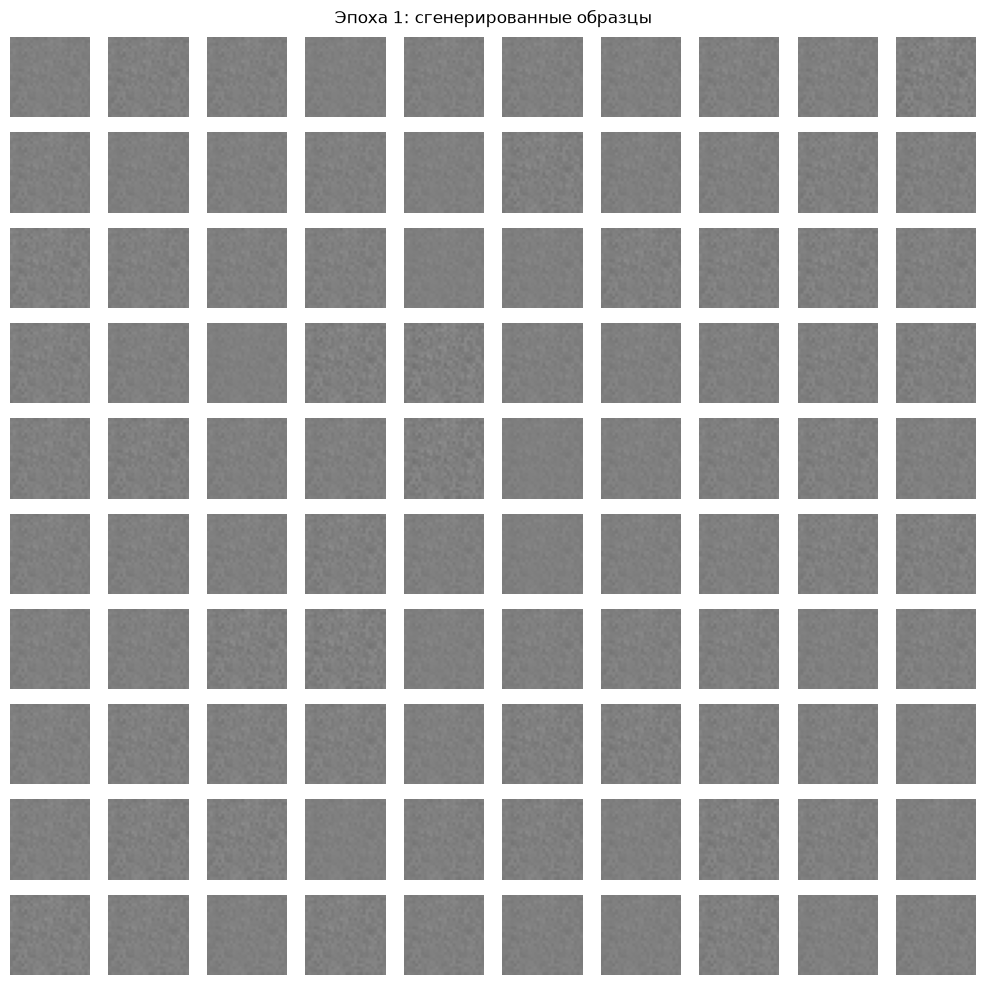

Эпоха 001: L_D=0.5238; L_G=0.7656


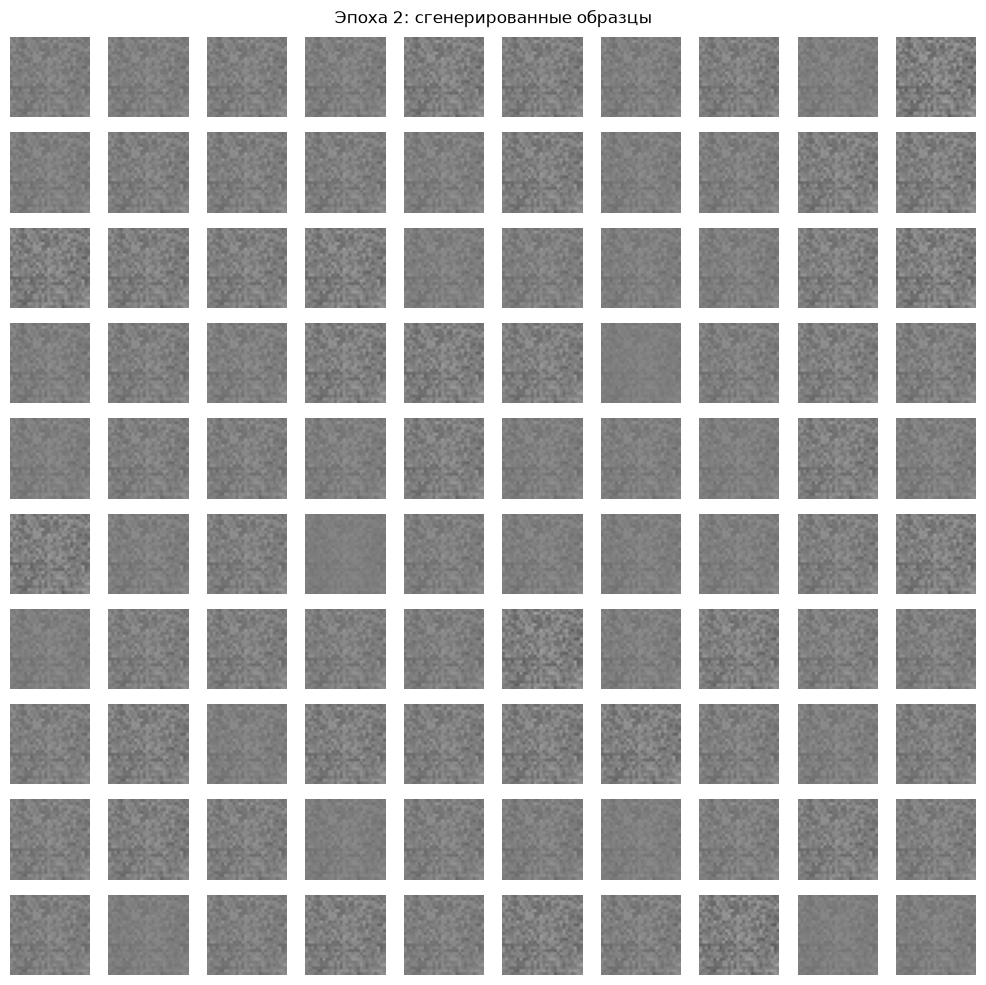

Эпоха 002: L_D=0.3860; L_G=2.2275


Эпоха 003: L_D=0.3290; L_G=3.6808


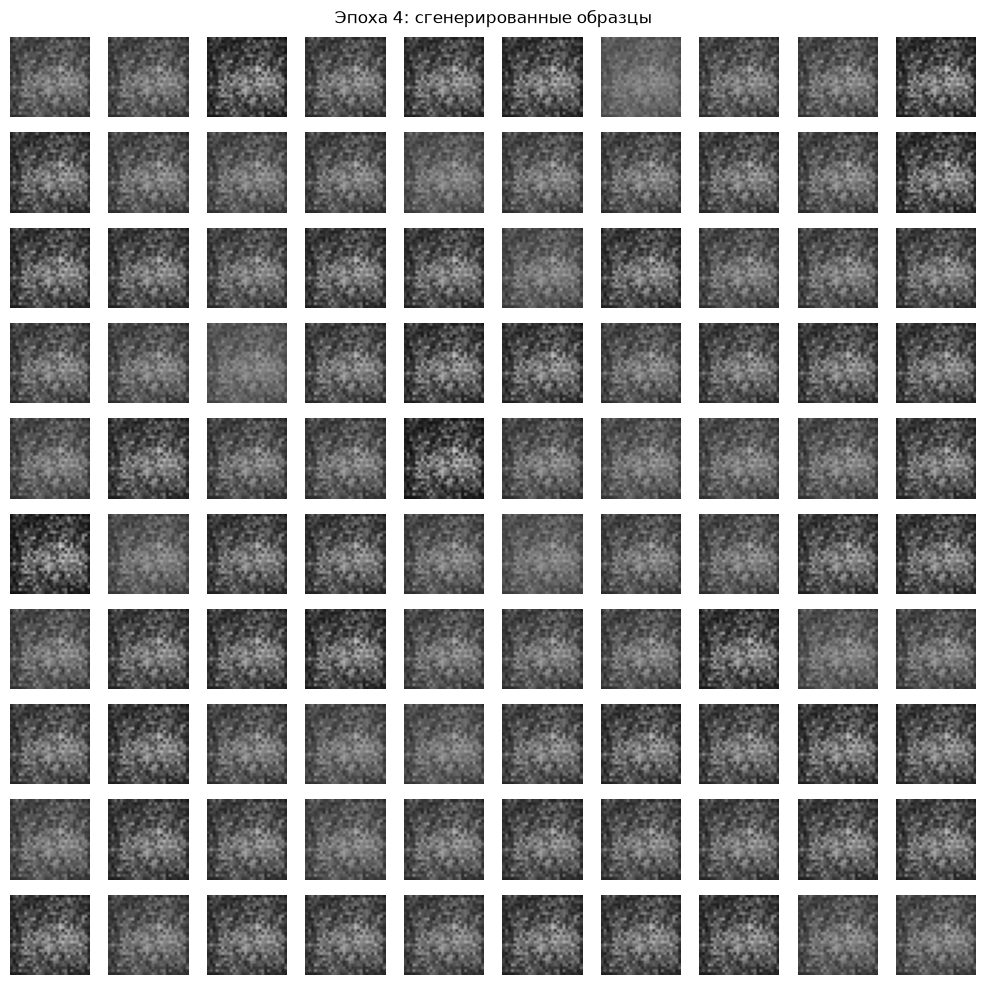

Эпоха 004: L_D=0.3586; L_G=4.6834


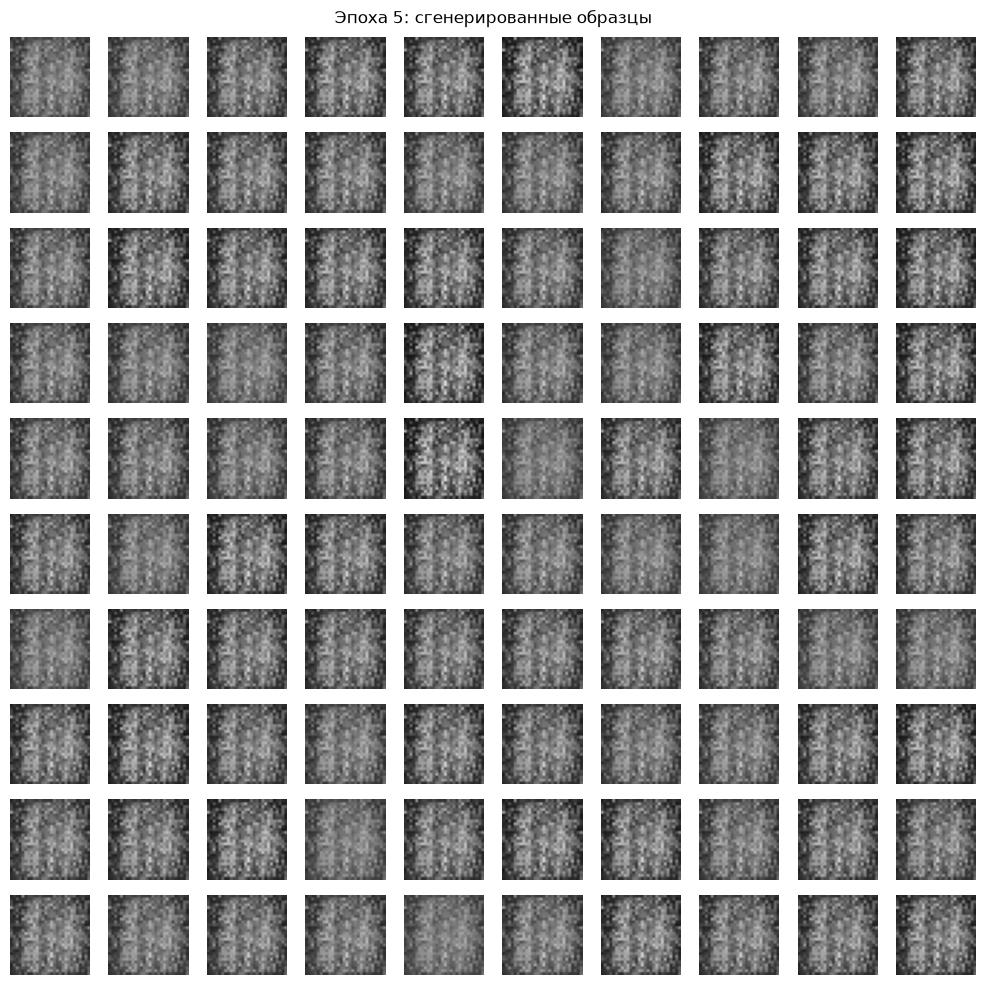

Эпоха 005: L_D=0.3004; L_G=4.3450


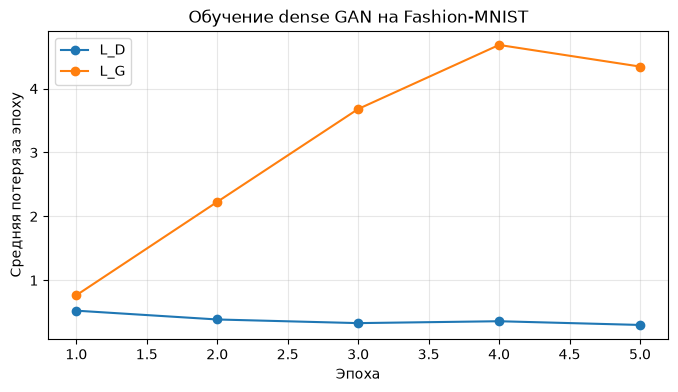

Число эпох в этом запуске: 5
Итоговые потери: L_D=0.3004, L_G=4.3450
Сохранённые сетки: [1, 2, 4, 5]
Примечание: полный профиль из 105/205/400 эпох на CPU занимает часы, поэтому здесь выполнен короткий учебный прогон; архитектура, нормализация и процедура полностью соответствуют заданию.


In [6]:
fixed_noise = tf.random.normal((100, NOISE_DIM))
history = {'d_loss': [], 'g_loss': []}
snapshots: dict[int, np.ndarray] = {}


def save_grid(images: np.ndarray, title: str, path: Path) -> None:
    figure, axes = plt.subplots(10, 10, figsize=(10, 10))
    for index, axis in enumerate(axes.flat):
        axis.imshow(images[index] * 0.5 + 0.5, cmap='gray', vmin=0, vmax=1)
        axis.axis('off')
    figure.suptitle(title)
    figure.tight_layout()
    figure.savefig(path, dpi=110)
    plt.show()
    plt.close(figure)


for epoch in range(1, EPOCHS + 1):
    batch_losses_d, batch_losses_g = [], []
    for real_images in dataset:
        loss_d, loss_g = train_step(real_images)
        batch_losses_d.append(float(loss_d))
        batch_losses_g.append(float(loss_g))

    history['d_loss'].append(float(np.mean(batch_losses_d)))
    history['g_loss'].append(float(np.mean(batch_losses_g)))

    if epoch == 1 or epoch % SAVE_EVERY == 0 or epoch == EPOCHS:
        generated = generator(fixed_noise, training=False).numpy()
        images = generated.reshape(100, IMAGE_HEIGHT, IMAGE_WIDTH)
        snapshots[epoch] = images
        save_grid(images, f'Эпоха {epoch}: сгенерированные образцы', artifact_dir / f'epoch_{epoch:03d}.png')

    print(
        f'Эпоха {epoch:03d}: L_D={history["d_loss"][-1]:.4f}; '
        f'L_G={history["g_loss"][-1]:.4f}'
    )

plt.figure(figsize=(8, 4))
epochs = range(1, len(history['d_loss']) + 1)
plt.plot(epochs, history['d_loss'], marker='o', label='L_D')
plt.plot(epochs, history['g_loss'], marker='o', label='L_G')
plt.xlabel('Эпоха')
plt.ylabel('Средняя потеря за эпоху')
plt.title('Обучение dense GAN на Fashion-MNIST')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print('Число эпох в этом запуске:', len(epochs))
print('Итоговые потери: L_D=%.4f, L_G=%.4f' % (history['d_loss'][-1], history['g_loss'][-1]))
print('Сохранённые сетки:', sorted(snapshots))
print(
    'Примечание: полный профиль из 105/205/400 эпох на CPU занимает часы, '
    'поэтому здесь выполнен короткий учебный прогон; архитектура, нормализация '
    'и процедура полностью соответствуют заданию.'
)

## Этап 7. Итоговая самопроверка

- Использован именно Fashion-MNIST, а не MNIST из примера.
- Шум имеет форму $(B,100)$; реальные и синтетические изображения —
  $(B,784)$; ответ дискриминатора — $(B,1)$.
- Реальные значения нормированы к $[-1,1]$, как и выход tanh
  генератора.
- Метки классов одежды не входят в BinaryCrossentropy GAN.
- Генератор и дискриминатор обновляются отдельными оптимизаторами.
- Сетки и две истории потерь сохранены для всех трёх экспериментов.